# Step 2b — Six-slot cache with header-derived sequence typing

Replaces the 3-slot cache. Two changes, both taken from the 0.940 notebook:

**Six slots instead of three.** The old cache kept one series per plane, preferring
fluid-sensitive, and **threw the T1 away**. Fluid-sensitive shows pathology; T1 shows
anatomy and marrow. Half the available imaging was being discarded at cache time.

```
0 SAG_FLUID_FS   1 COR_FLUID_FS   2 AX_FLUID_FS
3 SAG_FLUID_NOFS 4 COR_T1         5 SAG_T1
```

**Sequence type derived from DICOM headers, not the provided flags.** `Fluid_Sensitive`
and `Fat_Suppression` are two bits; the headers carry SeriesDescription, SequenceName,
ScanOptions, TR, TE and ScanningSequence. We recover T1/T2/PD/GRE properly and fall
back to the provided flags only where the headers are silent.

Also: **`SLICE_BAND = (0.2, 0.8)`** — sample only the central 60% of each stack. The
outer slices are usually off-joint.

**Setup:** attach the competition. Internet **ON** (JPEG decoders). Accelerator
**None** — CPU-bound, don't spend GPU quota.

## 0 · Config and size budget

In [1]:
import os, sys, glob, json, time, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
if not os.path.isdir(DATA_DIR):
    DATA_DIR = "/kaggle/input/rsna-knee-abnormality-detection"
WORK = "/kaggle/working"

IMG      = 224
N_SLICES = 12            # 6 slots x 16 x 224 would be 21.2 GB -- over the 20 GB cap
SLICE_BAND = (0.2, 0.8)  # central 60% of the stack; the ends are usually off-joint
MIN_SLICES = 8

# (name, plane, fluid_sensitive, fat_suppressed)
SLOTS = [
    ("SAG_FLUID_FS",   "Sagittal", True,  True),
    ("COR_FLUID_FS",   "Coronal",  True,  True),
    ("AX_FLUID_FS",    "Axial",    True,  True),
    ("SAG_FLUID_NOFS", "Sagittal", True,  False),
    ("COR_T1",         "Coronal",  False, None),
    ("SAG_T1",         "Sagittal", False, None),
]
SLOT_NAMES = [s[0] for s in SLOTS]
N_SLOTS = len(SLOTS)

CACHE = os.path.join(WORK, "cache.npy")
INDEX = os.path.join(WORK, "cache_index.csv")
STATE = os.path.join(WORK, "cache_done.npy")
SLOTJ = os.path.join(WORK, "slots.json")

assert os.path.isdir(DATA_DIR), f"attach the competition ({DATA_DIR} missing)"
print("competition files:", sorted(os.listdir(DATA_DIR)))

competition files: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']


In [2]:
n_std = len(pd.read_csv(os.path.join(DATA_DIR, "train.csv")))
gb = N_SLOTS * N_SLICES * IMG * IMG * n_std / 1e9
print(f"{n_std:,} studies x {N_SLOTS} slots x {N_SLICES} slices x {IMG}px = {gb:.1f} GB")
assert gb < 19, "over the 20 GB output cap -- lower N_SLICES or IMG"
print(f"in-joint slice density: {N_SLICES} across the central "
      f"{100*(SLICE_BAND[1]-SLICE_BAND[0]):.0f}% "
      f"(the old cache put {16*(SLICE_BAND[1]-SLICE_BAND[0]):.1f} there)")

try:
    import pylibjpeg, pylibjpeg_libjpeg, pylibjpeg_openjpeg   # noqa: F401
    print("\npylibjpeg backends present")
except ImportError:
    !pip install -q pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg
    print("\ninstalled pylibjpeg backends")
import pydicom, cv2
print("pydicom", pydicom.__version__, "| cv2", cv2.__version__)

4,407 studies x 6 slots x 12 slices x 224px = 15.9 GB
in-joint slice density: 12 across the central 60% (the old cache put 9.6 there)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.8 MB/s eta 0:00:00

installed pylibjpeg backends
pydicom 3.0.2 | cv2 4.13.0


## 1 · Read one DICOM header per series

The competition gives you two bits per series. The headers carry far more, and the
0.940 pipeline leans on exactly these tags.

In [3]:
train        = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
train_series = pd.read_csv(os.path.join(DATA_DIR, "train_series.csv"))
train_series["series_dir"] = [
    os.path.join(DATA_DIR, "train_series", st, se)
    for st, se in zip(train_series["StudyInstanceUID"], train_series["SeriesInstanceUID"])]
print(f"{len(train):,} studies | {len(train_series):,} series")

HDR_TAGS = ["SeriesDescription", "SequenceName", "ScanOptions", "ScanningSequence",
            "RepetitionTime", "EchoTime", "InversionTime", "Laterality",
            "PixelSpacing", "MagneticFieldStrength", "Manufacturer"]


def read_header(series_dir):
    rec = {t: None for t in HDR_TAGS}
    rec["n_slices"] = 0
    files = glob.glob(os.path.join(series_dir, "*.dcm"))
    rec["n_slices"] = len(files)
    if not files:
        return rec
    for f in files[:3]:                      # first readable file wins
        try:
            ds = pydicom.dcmread(f, stop_before_pixels=True)
        except Exception:
            continue
        for t in HDR_TAGS:
            v = getattr(ds, t, None)
            if v is None:
                continue
            if t == "PixelSpacing":
                try: v = float(v[0])
                except Exception: v = None
            elif t in ("ScanOptions", "ScanningSequence") and not isinstance(v, str):
                v = "|".join(str(x) for x in v)
            elif not isinstance(v, (int, float, str)):
                v = str(v)
            rec[t] = v
        break
    return rec


from concurrent.futures import ThreadPoolExecutor
t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    hdrs = list(tqdm(ex.map(read_header, train_series["series_dir"]),
                     total=len(train_series), desc="headers", unit="series"))
hdr = pd.DataFrame(hdrs)
train_series = pd.concat([train_series.reset_index(drop=True), hdr], axis=1)
print(f"\nread {len(hdr):,} headers in {time.time()-t0:.0f}s")
print(f"SeriesDescription populated: {train_series['SeriesDescription'].notna().mean():.1%}")
print(f"Laterality populated       : {train_series['Laterality'].notna().mean():.1%}")
print(train_series["n_slices"].describe().round(1).to_string())

4,407 studies | 24,371 series


headers:   0%|          | 0/24371 [00:00<?, ?series/s]


read 24,371 headers in 93s
SeriesDescription populated: 94.1%
Laterality populated       : 79.1%
count    24371.0
mean        33.6
std         26.6
min         11.0
25%         25.0
50%         30.0
75%         34.0
max        320.0


## 2 · Derive sequence type, then check it against the provided flags

In [4]:
_SEP    = re.compile(r"[^a-z0-9]+")
_FATSAT = re.compile(r"\b(fs|fatsat|fatsuppressed|spair|spir|stir|dixon|spectral)\b")
_T1_RX  = re.compile(r"\bt1\b")
_T2_RX  = re.compile(r"\bt2\b")
_PD_RX  = re.compile(r"\b(pd|pdw|proton)\b")
FATSAT_OPTS = {"FS", "FSAT", "SFS", "SP", "SPIR", "SPAIR", "FATSAT"}


def annotate(df):
    desc = (df["SeriesDescription"].fillna("") + " " + df["SequenceName"].fillna(""))
    desc = desc.str.lower().str.replace(_SEP, " ", regex=True)

    opts = df["ScanOptions"].fillna("").str.upper().str.split("|")
    opts_fs = opts.apply(lambda ts: any(t.strip() in FATSAT_OPTS for t in ts))
    df["fatsat_hdr"] = desc.str.contains(_FATSAT) | opts_fs

    tr  = pd.to_numeric(df["RepetitionTime"], errors="coerce")
    te  = pd.to_numeric(df["EchoTime"], errors="coerce")
    gre = df["ScanningSequence"].fillna("").str.upper().str.contains("GR")
    t1, t2, pdw = desc.str.contains(_T1_RX), desc.str.contains(_T2_RX), desc.str.contains(_PD_RX)

    # name first, then fall back to the physics: short TR -> T1, long TE -> T2
    df["weight"] = np.where(t1 & ~t2 & ~pdw, "T1",
                    np.where(t2 & ~pdw, "T2",
                     np.where(pdw, "PD",
                      np.where(gre, "GRE",
                       np.where(tr < 800, "T1",
                        np.where(te > 60, "T2",
                         np.where(tr >= 800, "PD", "UNK")))))))
    df["fluid_hdr"] = np.isin(df["weight"], ["PD", "T2"])
    return df


train_series = annotate(train_series)

# Fall back to the organisers' flags wherever the headers were silent.
prov_fluid = pd.to_numeric(train_series["Fluid_Sensitive"], errors="coerce").fillna(0).astype(bool)
prov_fs    = pd.to_numeric(train_series["Fat_Suppression"], errors="coerce").fillna(0).astype(bool)
unk = train_series["weight"].eq("UNK")
train_series["fluid"]  = np.where(unk, prov_fluid, train_series["fluid_hdr"])
train_series["fatsat"] = np.where(train_series["SeriesDescription"].isna() &
                                  train_series["ScanOptions"].isna(),
                                  prov_fs, train_series["fatsat_hdr"])

print("derived sequence weighting:")
print(train_series["weight"].value_counts().to_string())
print(f"\nUNK (fell back to the provided flag): {unk.mean():.1%}")
print("\nagreement with the organisers' flags:")
print(f"  fluid-sensitive : {(train_series['fluid'] == prov_fluid).mean():.1%}")
print(f"  fat-suppressed  : {(train_series['fatsat'] == prov_fs).mean():.1%}")
print("\nThe disagreements are the point -- that is information the two provided")
print("bits did not carry. Spot-check a few before trusting it wholesale:")
dis = train_series[train_series["fluid"] != prov_fluid]
print(dis[["SeriesDescription", "RepetitionTime", "EchoTime", "weight",
           "Fluid_Sensitive"]].head(8).to_string(index=False))

derived sequence weighting:
weight
PD     13888
T1      5251
T2      4397
UNK      600
GRE      235

UNK (fell back to the provided flag): 2.5%

agreement with the organisers' flags:
  fluid-sensitive : 80.5%
  fat-suppressed  : 92.6%

The disagreements are the point -- that is information the two provided
bits did not carry. Spot-check a few before trusting it wholesale:
              SeriesDescription  RepetitionTime  EchoTime weight  Fluid_Sensitive
                      DP CS_SAG     3493.437256    10.000     PD                0
int_tse_sag_p3_s2_2.5mm_drb_384     2200.000000    32.000     PD                0
           t2_tse_sag_448_2.5mm     3470.000000    74.000     T2                0
                  LT_t2_tse_sag     6670.000000    73.000     T2                0
                  LT_t2_tse_cor     7360.000000    73.000     T2                0
                 RT. PD_TSE_SAG     2320.000000    38.000     PD                0
                     Sag T2 FSE     6483.000000    

## 3 · Assign the six slots

In [5]:
def choose(g):
    picked = {}
    for name, plane, fluid, fs in SLOTS:
        sel = (g["plane"] == plane) & (g["fluid"] == fluid)
        if fs is not None:
            sel = sel & (g["fatsat"] == fs)
        cand = g[sel & (g["n_slices"] >= MIN_SLICES)]
        if not len(cand):
            cand = g[sel]
        if len(cand):
            picked[name] = cand.sort_values("n_slices", ascending=False).iloc[0]
    return picked


train_series["plane"] = train_series["Anatomical_Plane"].astype(str)

rows = []
for uid, g in tqdm(train_series.groupby("StudyInstanceUID", sort=False),
                   total=train_series["StudyInstanceUID"].nunique(),
                   desc="assigning slots", unit="study"):
    picked = choose(g)
    rec = {"StudyInstanceUID": uid}
    for i, name in enumerate(SLOT_NAMES):
        s = picked.get(name)
        rec[f"dir_{i}"] = s["series_dir"] if s is not None else ""
        rec[f"nsl_{i}"] = int(s["n_slices"]) if s is not None else 0
    rows.append(rec)

manifest = train[["StudyInstanceUID"]].merge(pd.DataFrame(rows),
                                             on="StudyInstanceUID", how="left")
for i in range(N_SLOTS):
    manifest[f"dir_{i}"] = manifest[f"dir_{i}"].fillna("")
    manifest[f"nsl_{i}"] = manifest[f"nsl_{i}"].fillna(0).astype(int)

print("slot coverage:")
for i, name in enumerate(SLOT_NAMES):
    print(f"  {i} {name:<16} {(manifest[f'dir_{i}'] != '').mean():6.1%}")
n_have = sum((manifest[f"dir_{i}"] != "").astype(int) for i in range(N_SLOTS))
print("\nslots per study:", n_have.value_counts().sort_index().to_dict())
print("studies with none:", int((n_have == 0).sum()))
print("\nThe old 3-slot cache carried at most 3 of these. Anything above 3 here is")
print("imaging the previous model never saw.")

assigning slots:   0%|          | 0/4407 [00:00<?, ?study/s]

slot coverage:
  0 SAG_FLUID_FS      98.5%
  1 COR_FLUID_FS      97.0%
  2 AX_FLUID_FS       91.3%
  3 SAG_FLUID_NOFS    51.2%
  4 COR_T1            64.2%
  5 SAG_T1            42.7%

slots per study: {2: 150, 3: 449, 4: 1426, 5: 2037, 6: 345}
studies with none: 0

The old 3-slot cache carried at most 3 of these. Anything above 3 here is
imaging the previous model never saw.


## 4 · Decoder (same fixes as before, plus SLICE_BAND)

In [6]:
def _sort_key(ds):
    # Canonicalise direction: the normal's sign depends on how the scanner wrote
    # ImageOrientationPatient, so force its dominant component positive.
    iop = getattr(ds, "ImageOrientationPatient", None)
    ipp = getattr(ds, "ImagePositionPatient", None)
    if iop is not None and ipp is not None:
        try:
            n = np.cross(np.array(iop[:3], float), np.array(iop[3:6], float))
            n = n * np.sign(n[np.argmax(np.abs(n))] or 1.0)
            return float(np.dot(np.array(ipp, float), n))
        except Exception:
            pass
    return float(getattr(ds, "InstanceNumber", 0) or 0)


def load_series(series_dir, n_slices=N_SLICES, img=IMG, band=SLICE_BAND):
    files = glob.glob(os.path.join(series_dir, "*.dcm"))
    if not files:
        raise FileNotFoundError(series_dir)
    keyed = []
    for f in files:
        try:
            keyed.append((_sort_key(pydicom.dcmread(f, stop_before_pixels=True)), f))
        except Exception:
            continue
    if not keyed:
        raise RuntimeError("no readable headers")
    keyed.sort(key=lambda t: t[0])
    ordered = [f for _, f in keyed]

    # central band only -- the first and last fifth of a stack are usually off-joint
    n = len(ordered)
    lo, hi = int(band[0] * (n - 1)), int(band[1] * (n - 1))
    idx = (np.linspace(lo, hi, n_slices).round().astype(int) if hi > lo
           else np.full(n_slices, n // 2))

    out = np.zeros((n_slices, img, img), dtype=np.float32)
    ok = 0
    for j, i in enumerate(idx):
        try:
            ds = pydicom.dcmread(ordered[int(i)])
            a = ds.pixel_array.astype(np.float32)
            m = float(getattr(ds, "RescaleSlope", 1) or 1)
            b = float(getattr(ds, "RescaleIntercept", 0) or 0)
            if (m, b) != (1.0, 0.0):
                a = a * m + b
            if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
                a = a.max() - a
            if a.ndim == 3:
                a = a.mean(axis=-1)
            out[j] = cv2.resize(a, (img, img), interpolation=cv2.INTER_AREA)
            ok += 1
        except Exception:
            continue
    if ok == 0:
        raise RuntimeError("no decodable slices")

    lo_v, hi_v = np.percentile(out, [1, 99])     # whole volume: shift/scale invariant
    if hi_v <= lo_v:
        lo_v, hi_v = float(out.min()), float(out.max())
    if hi_v <= lo_v:
        hi_v = lo_v + 1.0
    return np.clip((out - lo_v) / (hi_v - lo_v) * 255.0, 0, 255).astype(np.uint8)

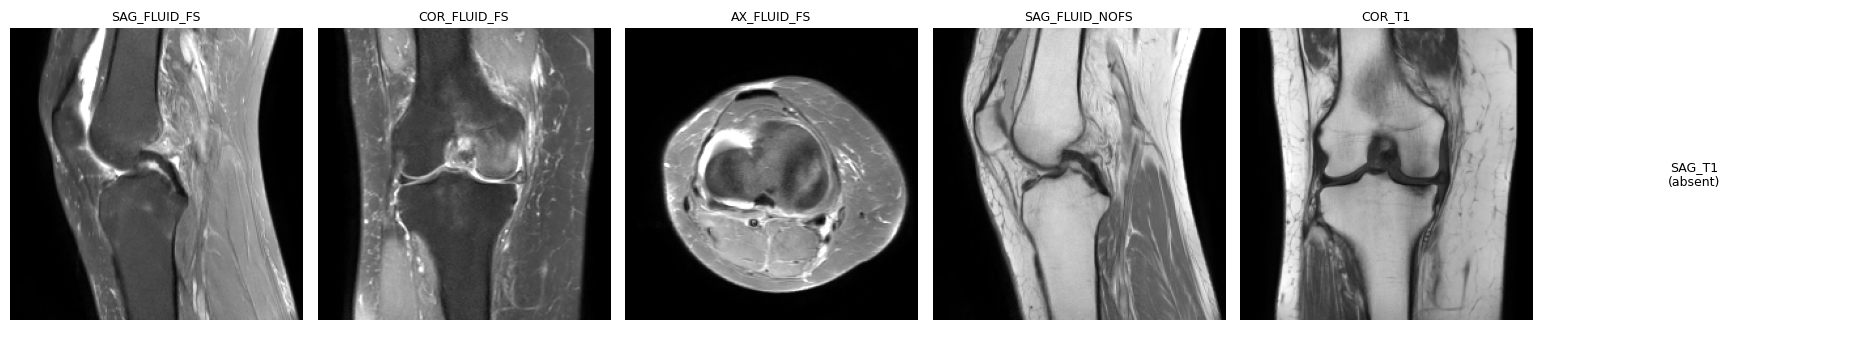

0.37s per series | projected full run: 30 min
T1 slots should look anatomical (bright fat, dark fluid); FLUID_FS slots the
opposite. If they look identical, the sequence typing is wrong.


In [7]:
# look at all six slots of one well-covered study before committing hours
probe = manifest[sum((manifest[f"dir_{i}"] != "").astype(int)
                     for i in range(N_SLOTS)) >= 5].iloc[0]
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, N_SLOTS, figsize=(3.1 * N_SLOTS, 3.4))
t0 = time.time(); n_done = 0
for i, ax in enumerate(axes):
    d = probe[f"dir_{i}"]
    if not d:
        ax.text(.5, .5, f"{SLOT_NAMES[i]}\n(absent)", ha="center", va="center", fontsize=9)
        ax.axis("off"); continue
    v = load_series(d); n_done += 1
    ax.imshow(v[len(v) // 2], cmap="gray", vmin=0, vmax=255)
    ax.set_title(SLOT_NAMES[i], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
per = (time.time() - t0) / max(n_done, 1)
print(f"{per:.2f}s per series | projected full run: "
      f"{per * int((manifest[[f'dir_{i}' for i in range(N_SLOTS)]] != '').sum().sum()) / max(os.cpu_count(),1) / 60:.0f} min")
print("T1 slots should look anatomical (bright fat, dark fluid); FLUID_FS slots the")
print("opposite. If they look identical, the sequence typing is wrong.")

## 5 · Fill the cache

In [8]:
N = len(manifest)
SHAPE = (N, N_SLOTS, N_SLICES, IMG, IMG)
print(f"cache {SHAPE} -> {np.prod(SHAPE)/1e9:.1f} GB")
assert np.prod(SHAPE) < 19e9

if not os.path.exists(CACHE):
    np.lib.format.open_memmap(CACHE, mode="w+", dtype=np.uint8, shape=SHAPE).flush()
    print("allocated", CACHE)
done = np.load(STATE) if os.path.exists(STATE) else np.zeros(N, dtype=bool)
present = np.zeros((N, N_SLOTS), dtype=bool)
if os.path.exists(INDEX):
    prev = pd.read_csv(INDEX)
    for i in range(N_SLOTS):
        present[:, i] = prev[f"present_{i}"].to_numpy(dtype=bool)
print(f"{done.sum():,}/{N:,} studies already cached")

cache (4407, 6, 12, 224, 224) -> 15.9 GB
allocated /kaggle/working/cache.npy
0/4,407 studies already cached


In [9]:
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

try:
    _CTX = mp.get_context("fork")
    def _pool(n): return ProcessPoolExecutor(max_workers=n, mp_context=_CTX)
    _KIND = "processes (fork)"
except ValueError:
    def _pool(n): return ThreadPoolExecutor(max_workers=n)
    _KIND = "threads"
print("parallelism:", _KIND, "|", os.cpu_count(), "cpus")

DIRS = [[manifest[f"dir_{i}"].iloc[r] for i in range(N_SLOTS)] for r in range(N)]


def fill_row(r):
    mm = np.lib.format.open_memmap(CACHE, mode="r+")
    filled = []
    for slot, d in enumerate(DIRS[r]):
        if not d:
            continue
        try:
            mm[r, slot] = load_series(d)
            filled.append(slot)
        except Exception:
            pass
    del mm
    return r, filled


todo = [r for r in range(N) if not done[r]]
t0 = time.time()
with _pool(os.cpu_count()) as ex:
    for k, (r, filled) in enumerate(tqdm(ex.map(fill_row, todo, chunksize=8),
                                         total=len(todo), desc="caching", unit="study"), 1):
        done[r] = True
        present[r, filled] = True
        if k % 250 == 0:
            np.save(STATE, done)
np.save(STATE, done)
print(f"\ncached {done.sum():,}/{N:,} in {(time.time()-t0)/60:.0f} min")

parallelism: processes (fork) | 4 cpus


caching:   0%|          | 0/4407 [00:00<?, ?study/s]


cached 4,407/4,407 in 36 min


## 6 · Verify, index, hand off

In [10]:
index = manifest[["StudyInstanceUID"]].copy()
for i in range(N_SLOTS):
    index[f"present_{i}"] = present[:, i]
index["row"] = np.arange(N)
index["n_present"] = present.sum(axis=1)
index.to_csv(INDEX, index=False)

with open(SLOTJ, "w") as f:
    json.dump({"slots": SLOT_NAMES, "n_slices": N_SLICES, "img": IMG,
               "slice_band": list(SLICE_BAND)}, f, indent=1)

print("decoded slots per study:", index["n_present"].value_counts().sort_index().to_dict())
print("\nper-slot success (decoded / assigned):")
for i, name in enumerate(SLOT_NAMES):
    want = int((manifest[f"dir_{i}"] != "").sum()); got = int(present[:, i].sum())
    print(f"  {name:<16} {got:,}/{want:,} ({got/max(want,1):.1%})")
print(f"\nstudies with NO usable slot: {int((index['n_present']==0).sum())}")
print(f"mean slots per study: {index['n_present'].mean():.2f}  (old cache capped at 3)")

decoded slots per study: {2: 150, 3: 449, 4: 1426, 5: 2037, 6: 345}

per-slot success (decoded / assigned):
  SAG_FLUID_FS     4,342/4,342 (100.0%)
  COR_FLUID_FS     4,276/4,276 (100.0%)
  AX_FLUID_FS      4,024/4,024 (100.0%)
  SAG_FLUID_NOFS   2,256/2,256 (100.0%)
  COR_T1           2,828/2,828 (100.0%)
  SAG_T1           1,880/1,880 (100.0%)

studies with NO usable slot: 0
mean slots per study: 4.45  (old cache capped at 3)


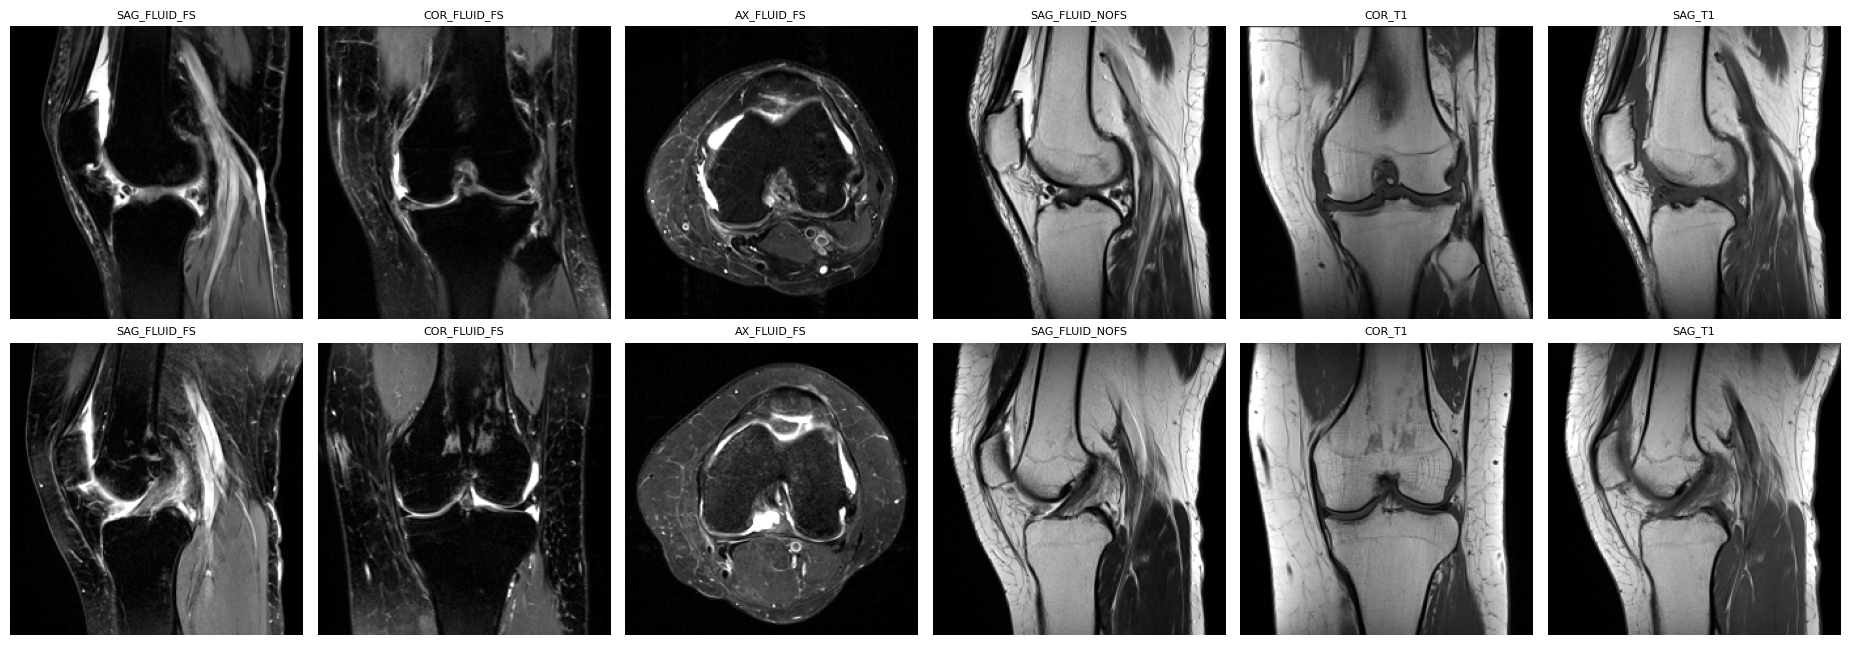

In [11]:
mm = np.load(CACHE, mmap_mode="r")
sample = index.sort_values("n_present", ascending=False).head(2)
fig, axes = plt.subplots(len(sample), N_SLOTS, figsize=(3.1*N_SLOTS, 3.3*len(sample)))
axes = np.atleast_2d(axes)
for a, (_, row) in enumerate(sample.iterrows()):
    for b in range(N_SLOTS):
        ax = axes[a, b]
        ax.imshow(mm[row["row"], b, N_SLICES//2], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{SLOT_NAMES[b]}{'' if row[f'present_{b}'] else ' (blank)'}", fontsize=8)
        ax.axis("off")
plt.tight_layout(); plt.show()

## 7 · Wiring it into training

The training notebook reads geometry from the cache, so `N_SLICES` and `IMG` follow
automatically. **Two things do not**, and both will break silently:

1. `PLANES` is a hard-coded list of three names. `KneeDS` builds its present-mask from
   `[f"present_{s}" for s in range(len(PLANES))]`, so it would read only three of six
   slots and the model would size `plane_emb` for three.
2. The plane-attention diagnostic labels its rows with `PLANES`.

Replace the `PLANES = [...]` line in the training config with:

```python
_slots = json.load(open(os.path.join(CACHE_DIR, "slots.json")))
PLANES = _slots["slots"]          # six names, in cache order
print("slots:", PLANES)
```

Everything else — `LabelAttnPool`, the present-mask, the diagnostic table — is written
in terms of `len(PLANES)` and adapts on its own.

**Expect training to roughly double** to ~0.66 s/step, ~11 min/epoch, ~90 min for 8
epochs. Still comfortable.

Worth trying once it runs: seed the per-label attention with the clinical prior from
the 0.940 notebook rather than letting it discover the anatomy — ACL on the sagittal
slots (0, 3, 5), MCL on coronal (1, 4), Baker's on slot 0 alone.